In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, roc_curve
)
from sklearn.utils import resample

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [4]:
data = pd.read_csv("/heart.csv")
print("shape of the data is", data.shape)

shape of the data is (303, 14)


In [7]:
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Two features have missing values: ca and thal

ca: 	number of major vessels (0-3) colored by flourosopy, 4 is a missing value

thal: thalassemia, a blood disease. 1: normal. 2: fixed defect. 3: reversible defect. 0: no values


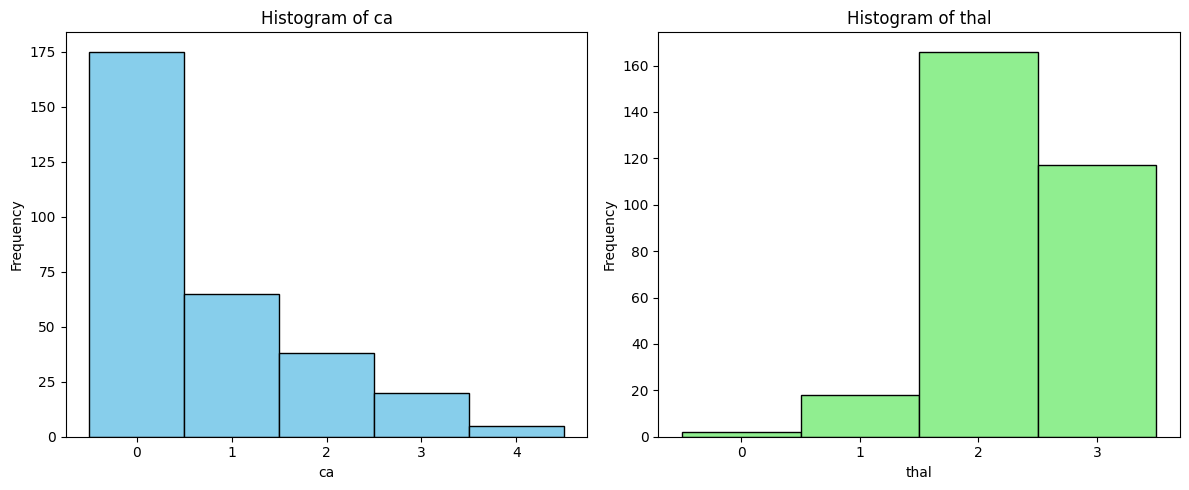

In [5]:
plt.figure(figsize=(12, 5))

# Subplot 1: Histogram of ca
plt.subplot(1, 2, 1)
plt.hist(data["ca"], bins=np.arange(-0.5, 5.5, 1), edgecolor='black', color='skyblue')
plt.title("Histogram of ca")
plt.xlabel("ca")
plt.ylabel("Frequency")
plt.xticks(range(5))

# Subplot 2: Histogram of thal
plt.subplot(1, 2, 2)
plt.hist(data["thal"], bins=np.arange(-0.5, 4.5, 1), edgecolor='black', color='lightgreen')
plt.title("Histogram of thal")
plt.xlabel("thal")
plt.ylabel("Frequency")
plt.xticks(range(4))

plt.tight_layout()
plt.show()

In [6]:
# remove missing data
data = data[data['ca'] < 4]
data = data[data['thal'] > 0]
print(f'The length of the data after preprocessing is {len(data)}')

The length of the data after preprocessing is 296


Rename the columns for clarity

In [7]:
data = data.rename(
    columns = {'cp':'chest_pain_type',
               'trestbps':'resting_blood_pressure',
               'chol': 'cholesterol',
               'fbs': 'fasting_blood_sugar>120mg/dl',
               'restecg' : 'resting_electrocardiogram',
               'thalach': 'max_heart_rate_achieved',
               'exang': 'exercise_induced_angina',
               'oldpeak': 'st_depression',
               'slope': 'st_slope',
               'ca':'num_major_vessels',
               'thal': 'thalassemia'},
    errors="raise")

In [8]:
data.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar>120mg/dl,resting_electrocardiogram,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


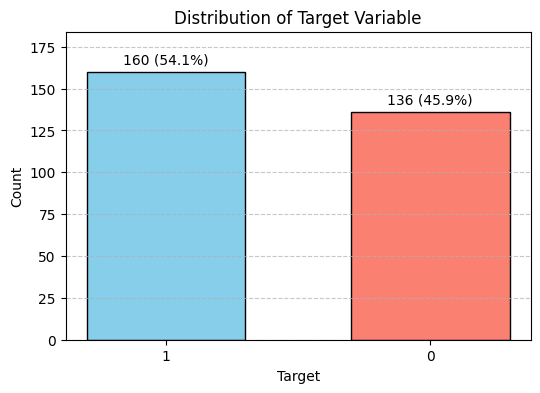

In [9]:
target_counts = data['target'].value_counts()
total = target_counts.sum()

plt.figure(figsize=(6, 4))
bars = plt.bar(target_counts.index.astype(str), target_counts.values, color=['skyblue', 'salmon'], edgecolor='black', width=0.6)

# Add percentage labels on top of the bars
for bar in bars:
    height = bar.get_height()
    percentage = (height / total) * 100
    plt.text(bar.get_x() + bar.get_width()/2., height + 3,
             f'{height} ({percentage:.1f}%)',
             ha='center', va='bottom', fontsize=10)

plt.title('Distribution of Target Variable')
plt.xlabel('Target')
plt.ylabel('Count')
plt.ylim(0, max(target_counts.values) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

About 54.1% of the patients have heart disease. About 45.9% of patients do not. The target is fairly balanced.

In [10]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,296.0,54.523649,9.059471,29.0,48.0,56.0,61.00,77.0
sex,296.0,0.679054,0.467631,0.0,0.0,1.0,1.00,1.0
chest_pain_type,296.0,0.959459,1.034184,0.0,0.0,1.0,2.00,3.0
resting_blood_pressure,296.0,131.604730,17.726620,94.0,120.0,130.0,140.00,200.0
cholesterol,296.0,247.155405,51.977011,126.0,211.0,242.5,275.25,564.0
fasting_blood_sugar>120mg/dl,296.0,0.145270,0.352970,0.0,0.0,0.0,0.00,1.0
resting_electrocardiogram,296.0,0.523649,0.526692,0.0,0.0,1.0,1.00,2.0
max_heart_rate_achieved,296.0,149.560811,22.970792,71.0,133.0,152.5,166.00,202.0
exercise_induced_angina,296.0,0.327703,0.470171,0.0,0.0,0.0,1.00,1.0
st_depression,296.0,1.059122,1.166474,0.0,0.0,0.8,1.65,6.2


In [11]:
#feature types
numerical_features = ['age', 'cholesterol', 'resting_blood_pressure', 'max_heart_rate_achieved', 'st_depression', 'num_major_vessels']
categorical_features = ['chest_pain_type', 'resting_electrocardiogram', 'fasting_blood_sugar>120mg/dl', 'exercise_induced_angina', 'st_slope', 'thalassemia']

In [12]:
# --- Preprocessor ---
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
])

y = data['target']
X = data.drop('target', axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- Logistic Regression ---
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
lr_params = {"classifier__C": [0.01, 0.1, 1, 10]}
lr_search = GridSearchCV(lr_pipeline, lr_params, cv=cv, scoring="roc_auc", n_jobs=-1)
lr_search.fit(X_train, y_train)
best_lr = lr_search.best_estimator_

# --- Random Forest ---
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42, n_jobs=-1)),
])
rf_params = {
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5],
}
rf_search = GridSearchCV(rf_pipeline, rf_params, cv=cv, scoring="roc_auc", n_jobs=-1)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

In [18]:
def bootstrap_metrics(model, X, y, n_bootstrap=1000, ci=0.95, random_state=42):
    """
    Returns a dict of {metric: (mean, lower, upper)} computed via bootstrap.
    """
    rng = np.random.RandomState(random_state)
    scores = {m: [] for m in ["accuracy", "roc_auc", "f1", "precision", "recall"]}

    for _ in range(n_bootstrap):
        X_bs, y_bs = resample(X, y, random_state=rng.randint(0, 99999))
        # Skip bootstrap samples with only one class
        if len(np.unique(y_bs)) < 2:
            continue
        y_pred = model.predict(X_bs)
        y_prob = model.predict_proba(X_bs)[:, 1]
        scores["accuracy"].append(accuracy_score(y_bs, y_pred))
        scores["roc_auc"].append(roc_auc_score(y_bs, y_prob))
        scores["f1"].append(f1_score(y_bs, y_pred, zero_division=0))
        scores["precision"].append(precision_score(y_bs, y_pred, zero_division=0))
        scores["recall"].append(recall_score(y_bs, y_pred, zero_division=0))

    alpha = (1 - ci) / 2
    results = {}
    for metric, vals in scores.items():
        vals = np.array(vals)
        results[metric] = (
            vals.mean(),
            np.percentile(vals, 100 * alpha),        # lower bound
            np.percentile(vals, 100 * (1 - alpha)),  # upper bound
        )
    return results

lr_ci = bootstrap_metrics(best_lr, X_test, y_test)
rf_ci = bootstrap_metrics(best_rf, X_test, y_test)

# --- Pretty-print results ---
print(f"{'Metric':<12} {'LR mean':>10} {'LR 95% CI':>22} {'RF mean':>10} {'RF 95% CI':>22}")
print("-" * 80)
for metric in ["accuracy", "roc_auc", "f1", "precision", "recall"]:
    lr_m, lr_lo, lr_hi = lr_ci[metric]
    rf_m, rf_lo, rf_hi = rf_ci[metric]
    print(
        f"{metric:<12} {lr_m:>10.3f} [{lr_lo:.3f}, {lr_hi:.3f}]"
        f"  {rf_m:>10.3f} [{rf_lo:.3f}, {rf_hi:.3f}]"
    )

Metric          LR mean              LR 95% CI    RF mean              RF 95% CI
--------------------------------------------------------------------------------
accuracy          0.800 [0.700, 0.900]       0.816 [0.717, 0.900]
roc_auc           0.881 [0.791, 0.955]       0.881 [0.789, 0.954]
f1                0.811 [0.700, 0.907]       0.833 [0.724, 0.919]
precision         0.810 [0.667, 0.941]       0.798 [0.658, 0.933]
recall            0.816 [0.676, 0.939]       0.876 [0.750, 0.971]


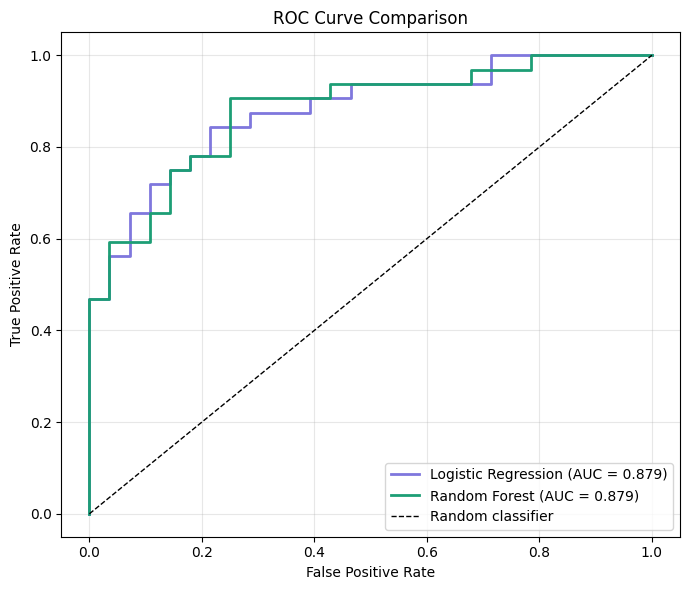

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))

for model, label, color in [
    (best_lr, "Logistic Regression", "#7F77DD"),
    (best_rf, "Random Forest",       "#1D9E75"),
]:
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{label} (AUC = {auc:.3f})", color=color, lw=2)

ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random classifier")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve Comparison")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

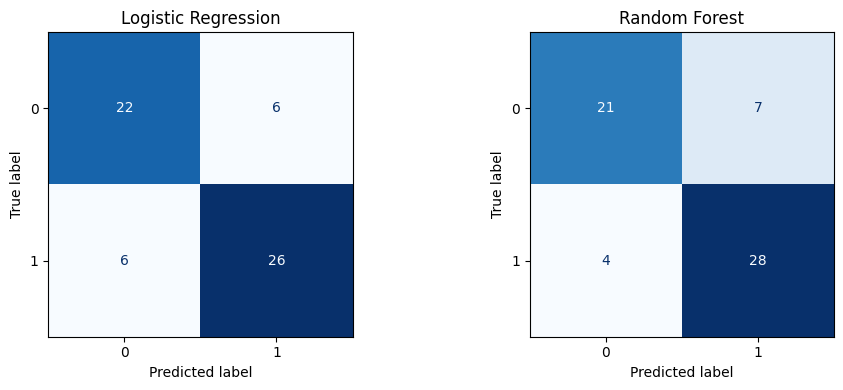

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, model, label in [
    (axes[0], best_lr, "Logistic Regression"),
    (axes[1], best_rf, "Random Forest"),
]:
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(label)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

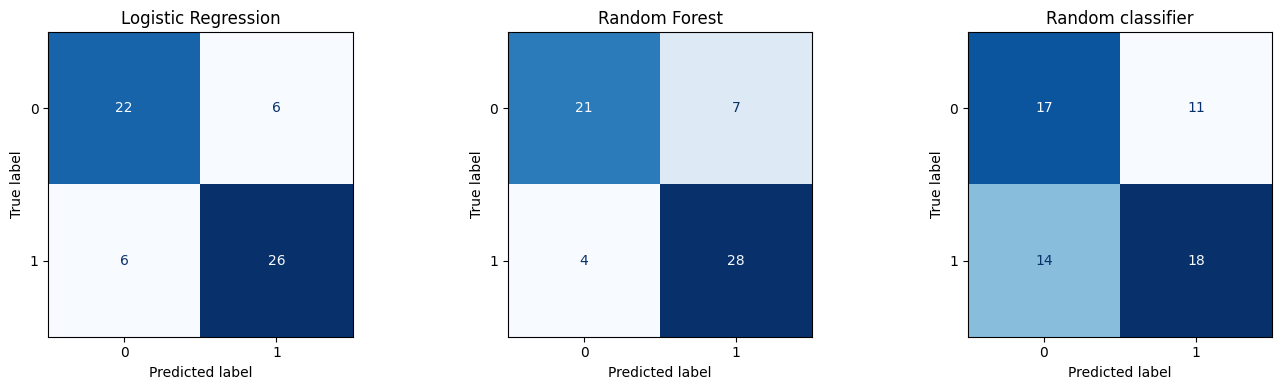

In [20]:
# Random classifier — predicts classes proportional to their frequency in training
class_probs = np.bincount(y_train) / len(y_train)
y_random = np.random.choice([0, 1], size=len(y_test), p=class_probs)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (y_pred, label) in zip(axes, [
    (best_lr.predict(X_test), "Logistic Regression"),
    (best_rf.predict(X_test), "Random Forest"),
    (y_random,                "Random classifier"),
]):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(
        ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(label)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

In [21]:
# major class classifier baseline
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_dummy = dummy.predict(X_test)
y_dummy_prob = dummy.predict_proba(X_test)[:, 1]

print("=== Baseline (majority class) ===")
print(f"Accuracy : {accuracy_score(y_test, y_dummy):.3f}")
print(f"F1       : {f1_score(y_test, y_dummy, zero_division=0):.3f}")
print(f"Precision: {precision_score(y_test, y_dummy, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_dummy, zero_division=0):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_dummy_prob):.3f}")

=== Baseline (majority class) ===
Accuracy : 0.533
F1       : 0.696
Precision: 0.533
Recall   : 1.000
ROC-AUC  : 0.500


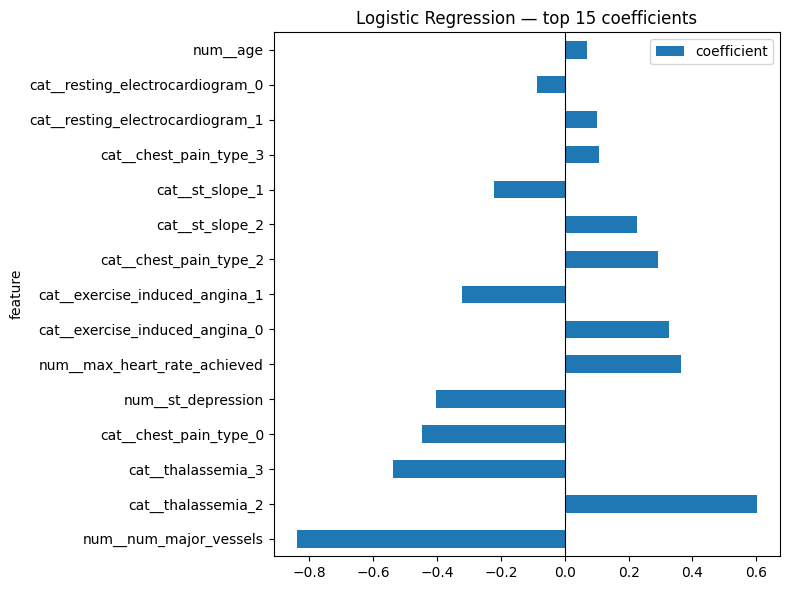

In [22]:
# coefficients for logistic regression
coef = best_lr.named_steps["classifier"].coef_[0]
feature_names = best_lr.named_steps["preprocessor"].get_feature_names_out()
feature_df = pd.DataFrame({"feature": feature_names, "coefficient": coef})
feature_df = feature_df.reindex(feature_df.coefficient.abs().sort_values(ascending=False).index)

feature_df.head(15).plot(kind="barh", x="feature", y="coefficient", figsize=(8, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression — top 15 coefficients")
plt.tight_layout()
plt.savefig("lr_coefficients.png", dpi=150)
plt.show()

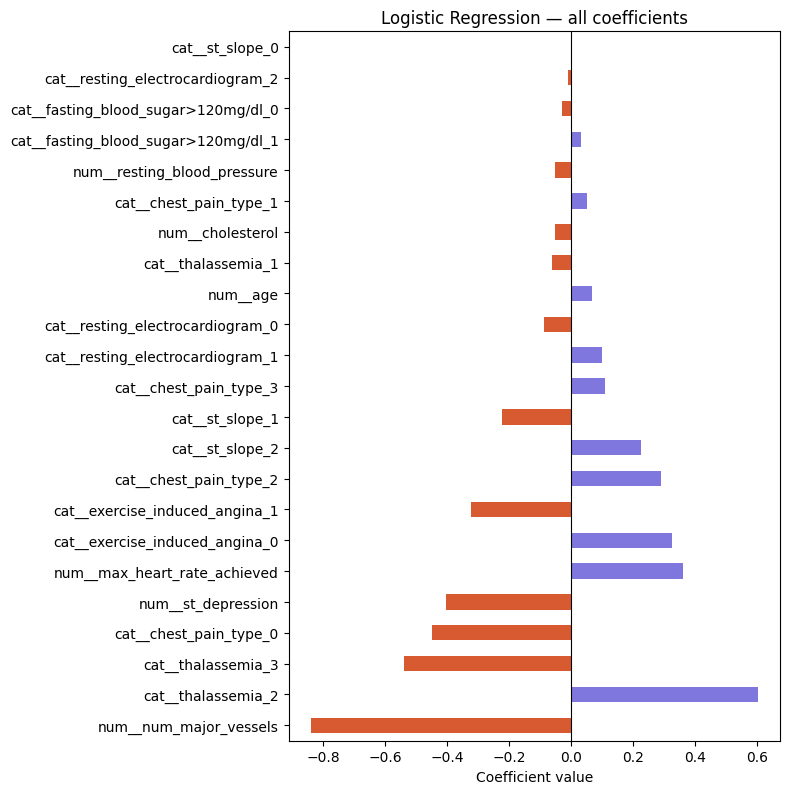

In [23]:
n_features = len(feature_df)

fig, ax = plt.subplots(figsize=(8, max(6, n_features * 0.35)))

feature_df.plot(
    kind="barh",
    x="feature",
    y="coefficient",
    ax=ax,
    legend=False,
    color=feature_df["coefficient"].apply(lambda x: "#7F77DD" if x > 0 else "#D85A30"),
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Logistic Regression — all coefficients")
ax.set_xlabel("Coefficient value")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("lr_coefficients_all.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
# Compute permutation importance on the test set
perm = permutation_importance(
    best_rf, X_test, y_test,
    n_repeats=30,          # number of times each feature is shuffled
    scoring="roc_auc",     # match the metric you care about
    random_state=42,
    n_jobs=-1,
)

feature_names = X_test.columns.tolist()

# Build a dataframe with mean and std across repeats
perm_df = pd.DataFrame({
    "feature":    feature_names,
    "importance": perm.importances_mean,
    "std":        perm.importances_std,
}).sort_values("importance", ascending=False)

print(perm_df.to_string(index=False))

                     feature  importance      std
                 thalassemia    0.062426 0.028792
           num_major_vessels    0.056250 0.027767
             chest_pain_type    0.045796 0.014709
                    st_slope    0.017783 0.014043
               st_depression    0.013690 0.014645
     exercise_induced_angina    0.010268 0.013649
                         age    0.004464 0.007158
      resting_blood_pressure    0.003051 0.007041
fasting_blood_sugar>120mg/dl    0.001897 0.002465
     max_heart_rate_achieved    0.000707 0.008112
                         sex    0.000000 0.000000
   resting_electrocardiogram   -0.000186 0.006412
                 cholesterol   -0.010417 0.005664


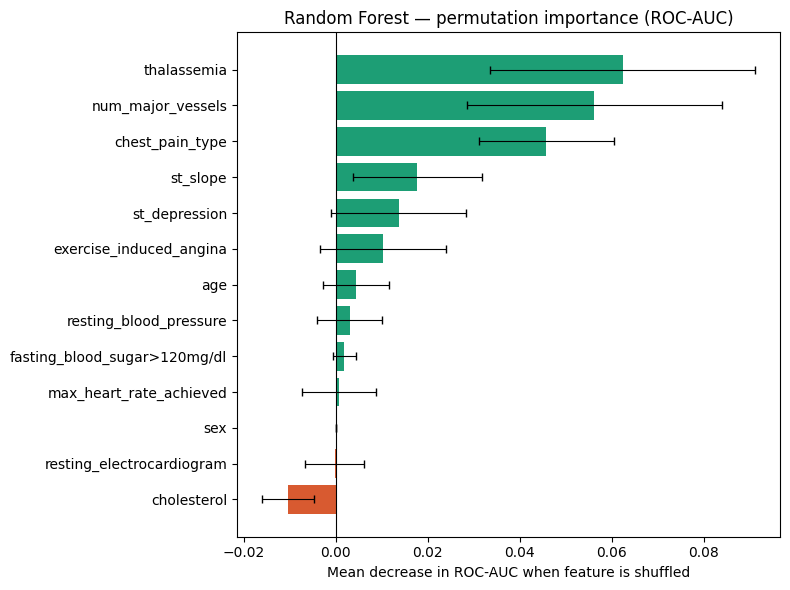

In [25]:
n_features = len(perm_df)

fig, ax = plt.subplots(figsize=(8, max(6, n_features * 0.35)))

ax.barh(
    perm_df["feature"],
    perm_df["importance"],
    xerr=perm_df["std"],
    color=[("#1D9E75" if v > 0 else "#D85A30") for v in perm_df["importance"]],
    error_kw={"linewidth": 0.8, "capsize": 3},
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Random Forest — permutation importance (ROC-AUC)")
ax.set_xlabel("Mean decrease in ROC-AUC when feature is shuffled")
ax.set_ylabel("")
ax.invert_yaxis()   # most important at top
plt.tight_layout()
plt.savefig("permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

Components for 90% variance: 10 of 23


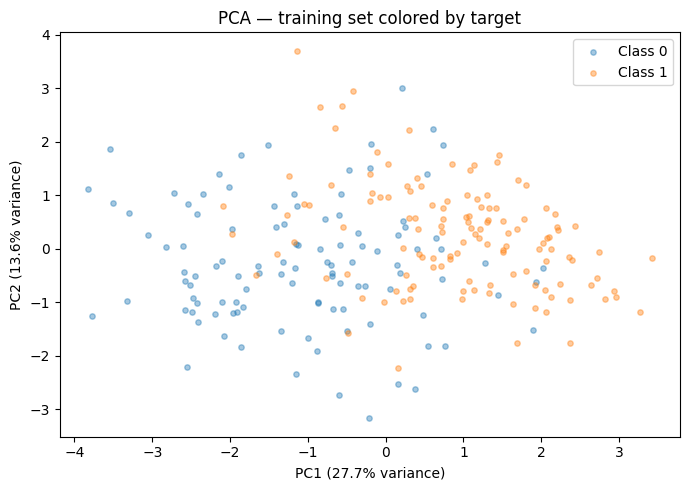


Cluster × target cross-tab (normalized by cluster):
target      0      1
row_0               
0       0.804  0.196
1       0.194  0.806


In [26]:
# Preprocess first (fit on train, transform both)
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

# PCA — check how many components capture 90% of variance
pca = PCA().fit(X_train_proc)
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_90 = np.argmax(cumvar >= 0.90) + 1
print(f"Components for 90% variance: {n_90} of {X_train_proc.shape[1]}")

# 2D PCA plot colored by target — does the data separate?
pca2 = PCA(n_components=2).fit(X_train_proc)
X_2d = pca2.transform(X_train_proc)
var_pc1, var_pc2 = pca2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(7, 5))
for label in np.unique(y_train):
    mask = y_train == label
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1], alpha=0.4, s=15, label=f"Class {label}")

ax.set_xlabel(f"PC1 ({var_pc1:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pc2:.1f}% variance)")
ax.set_title("PCA — training set colored by target")
ax.legend()
plt.tight_layout()
plt.savefig("pca_plot.png", dpi=150)
plt.show()

# K-means — check if clusters align with target
kmeans = KMeans(n_clusters=2, random_state=42, n_init="auto")
clusters = kmeans.fit_predict(X_train_proc)

print("\nCluster × target cross-tab (normalized by cluster):")
print(pd.crosstab(clusters, y_train, normalize="index").round(3))

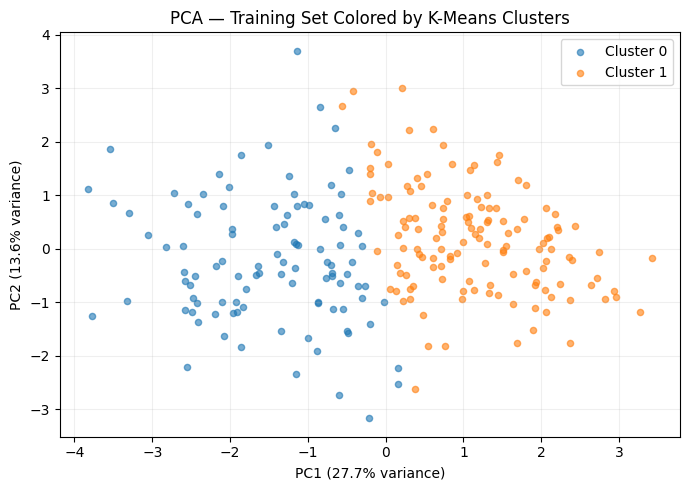

In [30]:
# Re-fit PCA on the preprocessed training set for 2 dimensions
pca2_km = PCA(n_components=2).fit(X_train_proc)
X_2d_km = pca2_km.transform(X_train_proc)
var_pc1_km, var_pc2_km = pca2_km.explained_variance_ratio_ * 100

# Fit K-means and predict labels
kmeans_model = KMeans(n_clusters=2, random_state=42, n_init="auto")
predicted_clusters = kmeans_model.fit_predict(X_train_proc)

# Plot the 2D projection colored by K-means clusters
fig, ax = plt.subplots(figsize=(7, 5))
for cluster_id in np.unique(predicted_clusters):
    mask = predicted_clusters == cluster_id
    ax.scatter(
        X_2d_km[mask, 0],
        X_2d_km[mask, 1],
        alpha=0.6,
        s=20,
        label=f"Cluster {cluster_id}"
    )

ax.set_xlabel(f"PC1 ({var_pc1_km:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pc2_km:.1f}% variance)")
ax.set_title("PCA — Training Set Colored by K-Means Clusters")
ax.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig("pca_kmeans_plot.png", dpi=150)
plt.show()

In [31]:
# Calculate the specific [FPR, TPR] points for both models
models_to_evaluate = [
    (best_lr, "Logistic Regression"),
    (best_rf, "Random Forest")
]

for model, name in models_to_evaluate:
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    print(f"=== {name} ROC Points [FPR, TPR] ===")
    points = [[round(f, 4), round(t, 4)] for f, t in zip(fpr, tpr)]
    for idx, pt in enumerate(points):
        print(f"Point {idx:2d}: {pt} (Threshold: {thresholds[idx]:.4f})")
    print()

=== Logistic Regression ROC Points [FPR, TPR] ===
Point  0: [np.float64(0.0), np.float64(0.0)] (Threshold: inf)
Point  1: [np.float64(0.0), np.float64(0.0312)] (Threshold: 0.9390)
Point  2: [np.float64(0.0), np.float64(0.4688)] (Threshold: 0.7680)
Point  3: [np.float64(0.0357), np.float64(0.4688)] (Threshold: 0.7569)
Point  4: [np.float64(0.0357), np.float64(0.5625)] (Threshold: 0.7435)
Point  5: [np.float64(0.0714), np.float64(0.5625)] (Threshold: 0.7349)
Point  6: [np.float64(0.0714), np.float64(0.6562)] (Threshold: 0.7274)
Point  7: [np.float64(0.1071), np.float64(0.6562)] (Threshold: 0.7257)
Point  8: [np.float64(0.1071), np.float64(0.7188)] (Threshold: 0.6898)
Point  9: [np.float64(0.1429), np.float64(0.7188)] (Threshold: 0.6574)
Point 10: [np.float64(0.1429), np.float64(0.75)] (Threshold: 0.6400)
Point 11: [np.float64(0.1786), np.float64(0.75)] (Threshold: 0.6231)
Point 12: [np.float64(0.1786), np.float64(0.7812)] (Threshold: 0.6121)
Point 13: [np.float64(0.2143), np.float64(0.78

In [17]:
from sklearn.metrics import accuracy_score
from sklearn.utils import resample

# Prepare testing dataframe containing unpredicted/raw demographic and clinical variables alongside targets and predictions
test_df = X_test.copy()
test_df['target'] = y_test
test_df['lr_pred'] = best_lr.predict(X_test)

# We will segment slices using 'age' (demographic) and 'sex' (demographic), which are not predicted variables
# Create age groups
age_bins = [0, 55, 65, 100]
age_labels = ['Under 55', '55 to 65', 'Over 65']
test_df['age_group'] = pd.cut(test_df['age'], bins=age_bins, labels=age_labels)
test_df['sex_label'] = test_df['sex'].map({1: 'Male', 0: 'Female'})

# Bootstrap helper to calculate interval
def get_accuracy_ci(df, n_bootstrap=1000, ci=0.95):
    if len(df) == 0:
        return np.nan, np.nan, np.nan
    accs = []
    rng = np.random.RandomState(42)
    for _ in range(n_bootstrap):
        df_bs = resample(df, random_state=rng)
        if len(df_bs) > 0:
            accs.append(accuracy_score(df_bs['target'], df_bs['lr_pred']))
    accs = np.array(accs)
    alpha = (1 - ci) / 2
    return accs.mean(), np.percentile(accs, 100 * alpha), np.percentile(accs, 100 * (1 - alpha))

print("=== Failure Analysis: Slicing Test Performance by Age Group and Sex (Exploratory) ===\n")
slices = []
for age_grp in age_labels:
    for sex_val in ['Male', 'Female']:
        slice_df = test_df[(test_df['age_group'] == age_grp) & (test_df['sex_label'] == sex_val)]
        size = len(slice_df)
        if size > 0:
            mean_acc, lo, hi = get_accuracy_ci(slice_df)
            slices.append({
                'slice_name': f"{age_grp} & {sex_val}",
                'size': size,
                'accuracy': mean_acc,
                'ci': (lo, hi)
            })

slices_df = pd.DataFrame(slices).sort_values(by='accuracy')
for idx, row in slices_df.iterrows():
    print(f"Slice: {row['slice_name']:<20} | Sample Size: {row['size']:<2} | Accuracy: {row['accuracy']:.3f} 95% CI: [{row['ci'][0]:.3f}, {row['ci'][1]:.3f}]")

worst_slice = slices_df.iloc[0]
print(f"\nWorst Slice Identified: '{worst_slice['slice_name']}' with accuracy of {worst_slice['accuracy']:.3f} (N={worst_slice['size']})")

=== Failure Analysis: Slicing Test Performance by Age Group and Sex (Exploratory) ===

Slice: Over 65 & Female     | Sample Size: 2  | Accuracy: 0.508 95% CI: [0.000, 1.000]
Slice: Under 55 & Male      | Sample Size: 20 | Accuracy: 0.750 95% CI: [0.550, 0.900]
Slice: 55 to 65 & Male      | Sample Size: 16 | Accuracy: 0.751 95% CI: [0.500, 0.938]
Slice: 55 to 65 & Female    | Sample Size: 10 | Accuracy: 0.799 95% CI: [0.500, 1.000]
Slice: Under 55 & Female    | Sample Size: 6  | Accuracy: 1.000 95% CI: [1.000, 1.000]
Slice: Over 65 & Male       | Sample Size: 6  | Accuracy: 1.000 95% CI: [1.000, 1.000]

Worst Slice Identified: 'Over 65 & Female' with accuracy of 0.508 (N=2)
